
FIRST FIVE RECORDS
  record_id age_group  age  weight  gender region smoking_status  \
0    HR0001     18-25   23      52  Female   East         Smoker   
1    HR0002       60+   66      82  Female  South     Non-Smoker   
2    HR0003     46-60   59      54    Male  North         Smoker   
3    HR0004     36-45   45      64    Male  South         Smoker   
4    HR0005     36-45   45      60    Male   East     Non-Smoker   

  exercise_frequency   bmi  blood_pressure  diabetes  hypertension  \
0             Rarely  24.8            91.0     False         False   
1              Never  30.6           134.2     False          True   
2             Weekly  22.8           120.6     False         False   
3             Weekly  17.3           111.6     False         False   
4             Rarely  16.5           134.1     False         False   

   cholesterol_level  glucose_level  visit_date  
0              153.4           60.0  2024-09-16  
1              210.0           92.0  2026-07-18  


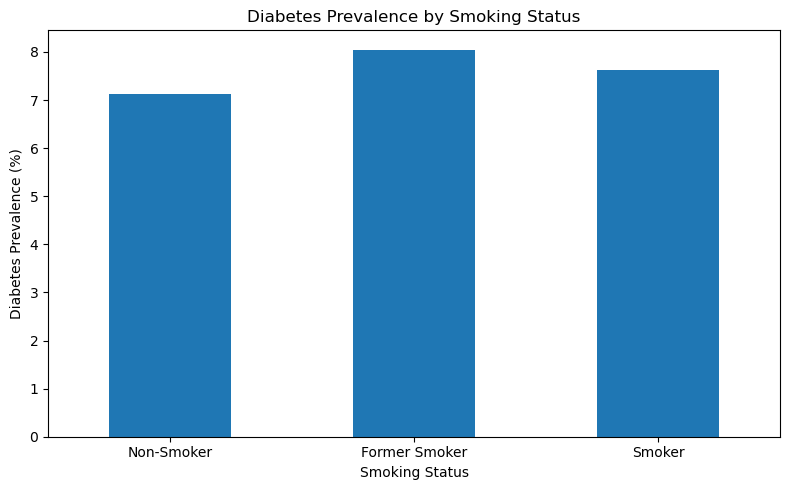

<Figure size 700x500 with 0 Axes>

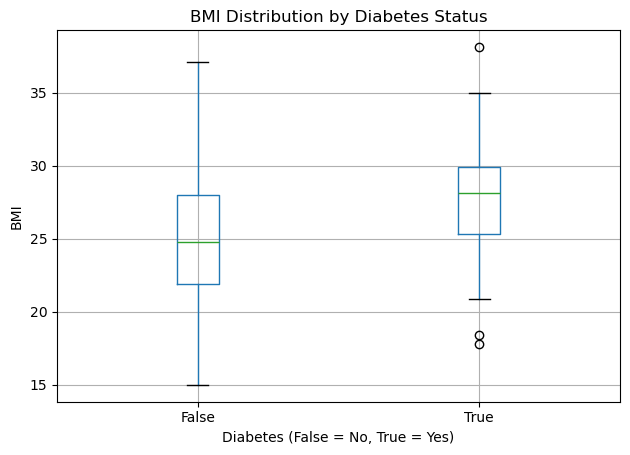

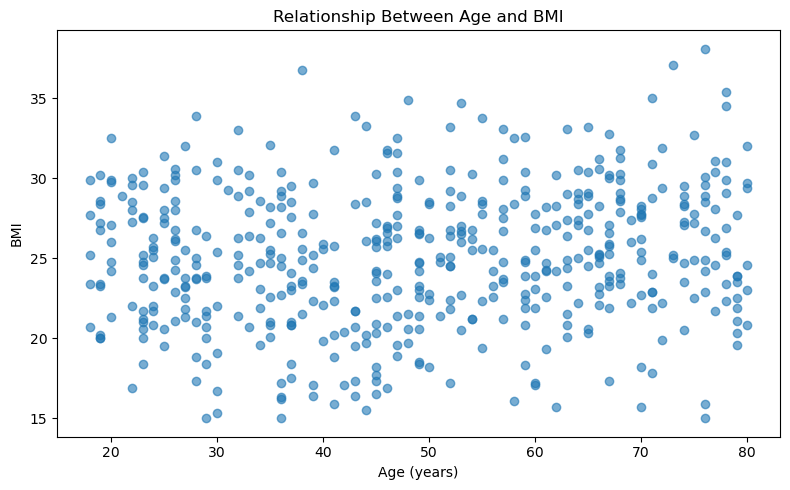


PROJECT SUMMARY
Total health records: 500
Diabetes cases: 37
Hypertension cases: 74
Mean age: 48.95
Mean BMI: 25.09

Significance level: 0.05
Rule: Reject H0 when p-value < 0.05.
Otherwise, fail to reject H0.

NOTE: This dataset is synthetic and intended
for educational statistical analysis only.
Association does not prove causation.


In [3]:

# Project: Derivable Judgement
# A Statistical Decision-Making Model

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# --------------------------------------------------
# 1.Loading CSV Dataset File
# --------------------------------------------------

file_name = "C:/Users/mansi/Downloads/derivable_judgement_health_dataset.csv"

if Path(file_name).exists():
    df = pd.read_csv(file_name)
else:
    np.random.seed(42)
    n = 500

    age = np.random.randint(18, 81, n)

    df = pd.DataFrame({
        "record_id": [f"HR{i:04d}" for i in range(1, n + 1)],
        "age": age,
        "weight": np.random.randint(40, 121, n),
        "gender": np.random.choice(
            ["Male", "Female", "Other"], n,
            p=[0.49, 0.49, 0.02]
        ),
        "region": np.random.choice(
            ["North", "South", "East", "West"], n
        ),
        "smoking_status": np.random.choice(
            ["Smoker", "Non-Smoker", "Former Smoker"], n,
            p=[0.22, 0.62, 0.16]
        ),
        "exercise_frequency": np.random.choice(
            ["Daily", "Weekly", "Rarely", "Never"], n
        ),
        "bmi": np.clip(
            np.random.normal(25 + (age - 40) * 0.03, 4, n),
            15, 45
        ).round(1),
        "blood_pressure": np.clip(
            np.random.normal(115 + (age - 40) * 0.4, 12, n),
            85, 205
        ).round(1),
        "cholesterol_level": np.clip(
            np.random.normal(190 + (age - 40) * 0.4, 25, n),
            100, 330
        ).round(1),
        "glucose_level": np.clip(
            np.random.normal(95 + (age - 40) * 0.2, 15, n),
            60, 240
        ).round(1),
        "visit_date": pd.to_datetime(
            np.random.choice(
                pd.date_range("2024-01-01", "2026-09-30"),
                n
            )
        ).strftime("%Y-%m-%d")
    })

    # Create age groups
    df["age_group"] = pd.cut(
        df["age"],
        bins=[17, 25, 35, 45, 60, 100],
        labels=["18-25", "26-35", "36-45", "46-60", "60+"]
    ).astype(str)

    # Generate disease indicators for educational use
    diabetes_probability = 1 / (
        1 + np.exp(-(
            -3.2
            + 0.045 * (df["age"] - 40)
            + 0.10 * (df["bmi"] - 25)
            + 0.015 * (df["glucose_level"] - 100)
        ))
    )

    hypertension_probability = 1 / (
        1 + np.exp(-(
            -2.5
            + 0.04 * (df["age"] - 40)
            + 0.07 * (df["bmi"] - 25)
            + 0.02 * (df["blood_pressure"] - 120)
        ))
    )

    df["diabetes"] = (
        np.random.random(n) < diabetes_probability
    )
    df["hypertension"] = (
        np.random.random(n) < hypertension_probability
    )

    # Arrange columns according to the project dataset structure
    df = df[[
        "record_id", "age_group", "age", "weight", "gender",
        "region", "smoking_status", "exercise_frequency",
        "bmi", "blood_pressure", "diabetes", "hypertension",
        "cholesterol_level", "glucose_level", "visit_date"
    ]]

    df.to_csv(file_name, index=False)
    print("Dataset created and saved successfully.")

# Convert Boolean columns if they were loaded as text
for col in ["diabetes", "hypertension"]:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str).str.lower().map({
            "true": True,
            "false": False
        })

# --------------------------------------------------
# 2. DISPLAY AND CHECK DATASET
# --------------------------------------------------

print("\nFIRST FIVE RECORDS")
print(df.head())

print("\nDATASET SHAPE:", df.shape)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDESCRIPTIVE STATISTICS")
print(df[[
    "age", "weight", "bmi", "blood_pressure",
    "cholesterol_level", "glucose_level"
]].describe().round(2))

# Significance level
alpha = 0.05

# --------------------------------------------------
# 3. HYPOTHESIS 1: SMOKING VS DIABETES
# Chi-square test
# --------------------------------------------------

print("\n" + "=" * 50)
print("TEST 1: CHI-SQUARE TEST")
print("Smoking Status vs Diabetes")
print("=" * 50)

# H0: Smoking status and diabetes are independent.
# H1: Smoking status and diabetes are associated.

table = pd.crosstab(
    df["smoking_status"], df["diabetes"]
)

chi2, p_value, dof, expected = stats.chi2_contingency(table)
critical_value = stats.chi2.ppf(1 - alpha, dof)

print("\nContingency Table:")
print(table)
print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("Critical value:", round(critical_value, 4))
print("P-value:", round(p_value, 6))

if p_value < alpha:
    print("Decision: Reject H0")
    print("Interpretation: Smoking status and diabetes show")
    print("a statistically significant association.")
else:
    print("Decision: Fail to reject H0")
    print("Interpretation: There is insufficient evidence")
    print("of an association between smoking and diabetes.")

# --------------------------------------------------
# 4. HYPOTHESIS 2: BMI VS DIABETES
# Welch's independent-samples t-test
# --------------------------------------------------

print("\n" + "=" * 50)
print("TEST 2: WELCH'S T-TEST")
print("BMI by Diabetes Status")
print("=" * 50)

# H0: Mean BMI is equal in both groups.
# H1: Mean BMI differs between the two groups.

bmi_yes = df.loc[df["diabetes"] == True, "bmi"].dropna()
bmi_no = df.loc[df["diabetes"] == False, "bmi"].dropna()

t_stat, p_value = stats.ttest_ind(
    bmi_yes, bmi_no, equal_var=False
)

# Welch-Satterthwaite degrees of freedom
v1 = bmi_yes.var(ddof=1) / len(bmi_yes)
v2 = bmi_no.var(ddof=1) / len(bmi_no)

df_t = (v1 + v2) ** 2 / (
    v1 ** 2 / (len(bmi_yes) - 1)
    + v2 ** 2 / (len(bmi_no) - 1)
)

critical_t = stats.t.ppf(1 - alpha / 2, df_t)

print("Mean BMI with diabetes:", round(bmi_yes.mean(), 2))
print("Mean BMI without diabetes:", round(bmi_no.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("Critical t-value: +/-", round(critical_t, 4))
print("P-value:", round(p_value, 6))

if p_value < alpha:
    print("Decision: Reject H0")
    print("Interpretation: Mean BMI differs significantly")
    print("between the two diabetes groups.")
else:
    print("Decision: Fail to reject H0")
    print("Interpretation: The difference in mean BMI")
    print("is not statistically significant.")

# --------------------------------------------------
# 5. 95% CONFIDENCE INTERVAL FOR MEAN AGE
# --------------------------------------------------

print("\n" + "=" * 50)
print("95% CONFIDENCE INTERVAL FOR MEAN AGE")
print("=" * 50)

ages = df["age"].dropna()
mean_age = ages.mean()
standard_error = stats.sem(ages)

ci_low, ci_high = stats.t.interval(
    0.95,
    df=len(ages) - 1,
    loc=mean_age,
    scale=standard_error
)

print("Mean age:", round(mean_age, 2))
print("95% Confidence Interval:",
      (round(ci_low, 2), round(ci_high, 2)))

# --------------------------------------------------
# 6. ANOVA: DIABETES RATE ACROSS AGE GROUPS
# --------------------------------------------------

print("\n" + "=" * 50)
print("TEST 3: ONE-WAY ANOVA")
print("Diabetes Rate Across Age Groups")
print("=" * 50)

# H0: Mean diabetes indicator is equal across age groups.
# H1: At least one age group has a different mean indicator.
# Since diabetes is coded 0/1, its group mean is the
# observed diabetes proportion in that group.

age_groups = ["18-25", "26-35", "36-45", "46-60", "60+"]

anova_groups = [
    df.loc[df["age_group"] == group, "diabetes"]
      .astype(int).dropna()
    for group in age_groups
]

f_stat, p_value = stats.f_oneway(*anova_groups)

group_count = len(anova_groups)
total_count = sum(len(group) for group in anova_groups)

critical_f = stats.f.ppf(
    1 - alpha,
    group_count - 1,
    total_count - group_count
)

print("Diabetes rate by age group (%):")
print(
    df.groupby("age_group", observed=False)["diabetes"]
      .mean().mul(100).round(2)
)

print("F-statistic:", round(f_stat, 4))
print("Critical F-value:", round(critical_f, 4))
print("P-value:", round(p_value, 6))

if p_value < alpha:
    print("Decision: Reject H0")
    print("Interpretation: Diabetes rates differ significantly")
    print("among at least some age groups.")
else:
    print("Decision: Fail to reject H0")
    print("Interpretation: There is insufficient evidence")
    print("of a difference in diabetes rates across age groups.")

# --------------------------------------------------
# 7. COVARIANCE AND CORRELATION: AGE VS BMI
# --------------------------------------------------

print("\n" + "=" * 50)
print("COVARIANCE AND CORRELATION")
print("Age vs BMI")
print("=" * 50)

covariance = df["age"].cov(df["bmi"])

correlation, corr_p = stats.pearsonr(
    df["age"], df["bmi"]
)

print("Covariance:", round(covariance, 4))
print("Pearson correlation:", round(correlation, 4))
print("Correlation p-value:", round(corr_p, 6))

if abs(correlation) < 0.3:
    strength = "weak"
elif abs(correlation) < 0.7:
    strength = "moderate"
else:
    strength = "strong"

if correlation > 0:
    direction = "positive"
elif correlation < 0:
    direction = "negative"
else:
    direction = "no"

print("Interpretation:", direction, strength, "linear correlation.")

# --------------------------------------------------
# 8. SECOND CHI-SQUARE TEST: EXERCISE VS HYPERTENSION
# --------------------------------------------------

print("\n" + "=" * 50)
print("TEST 4: CHI-SQUARE TEST")
print("Exercise Frequency vs Hypertension")
print("=" * 50)

# H0: Exercise frequency and hypertension are independent.
# H1: Exercise frequency and hypertension are associated.

table2 = pd.crosstab(
    df["exercise_frequency"], df["hypertension"]
)

chi2_2, p_2, dof_2, expected_2 = stats.chi2_contingency(table2)
critical_2 = stats.chi2.ppf(1 - alpha, dof_2)

print("\nContingency Table:")
print(table2)
print("Chi-square statistic:", round(chi2_2, 4))
print("Degrees of freedom:", dof_2)
print("Critical value:", round(critical_2, 4))
print("P-value:", round(p_2, 6))

if p_2 < alpha:
    print("Decision: Reject H0")
    print("Interpretation: Exercise frequency and hypertension")
    print("show a statistically significant association.")
else:
    print("Decision: Fail to reject H0")
    print("Interpretation: There is insufficient evidence")
    print("of an association between exercise and hypertension.")

# --------------------------------------------------
# 9. CHART 1: DIABETES PREVALENCE BY SMOKING STATUS
# --------------------------------------------------

smoking_rate = (
    df.groupby("smoking_status", observed=False)["diabetes"]
      .mean().mul(100)
      .reindex(["Non-Smoker", "Former Smoker", "Smoker"])
)

plt.figure(figsize=(8, 5))
smoking_rate.plot(kind="bar")
plt.title("Diabetes Prevalence by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Diabetes Prevalence (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. CHART 2: BMI BY DIABETES STATUS
# --------------------------------------------------

plt.figure(figsize=(7, 5))

df.boxplot(
    column="bmi",
    by="diabetes"
)

plt.title("BMI Distribution by Diabetes Status")
plt.suptitle("")
plt.xlabel("Diabetes (False = No, True = Yes)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 11. CHART 3: AGE VS BMI
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    df["age"],
    df["bmi"],
    alpha=0.6
)

plt.title("Relationship Between Age and BMI")
plt.xlabel("Age (years)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 12. FINAL SUMMARY
# --------------------------------------------------

print("\n" + "=" * 50)
print("PROJECT SUMMARY")
print("=" * 50)

print("Total health records:", len(df))
print("Diabetes cases:", int(df["diabetes"].sum()))
print("Hypertension cases:", int(df["hypertension"].sum()))
print("Mean age:", round(df["age"].mean(), 2))
print("Mean BMI:", round(df["bmi"].mean(), 2))

print("\nSignificance level:", alpha)
print("Rule: Reject H0 when p-value < 0.05.")
print("Otherwise, fail to reject H0.")

print("\nNOTE: This dataset is synthetic and intended")
print("for educational statistical analysis only.")
print("Association does not prove causation.")
